In [300]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("netflix_titles.csv",encoding="utf-8-sig")

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [301]:
print("Data Shape:",df.shape)
print("\nColumns name: ")
print(df.columns)
print("DataSet information:")
df.info()

Data Shape: (8807, 12)

Columns name: 
Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='str')
DataSet information:
<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [302]:
df.describe(include='all')

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


In [303]:
#to check null values in the dataset
df.isnull().sum()
#total null show is 4307 
#isnull is used to show missing values in data
#df.isnull() is a Pandas function used to identify missing (NULL or NaN) values in a dataset.

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [304]:
print("total missing values",df.isnull().sum().sum())
print("total Duplicate Rows:",df.duplicated().sum())
print("Dataset shape:", df.shape)

total missing values 4307
total Duplicate Rows: 0
Dataset shape: (8807, 12)


In [305]:
df["director"]=df["director"].fillna("Not specified")

df["cast"] = df["cast"].fillna("Not Available")

df["country"] = df["country"].fillna("Unknown")

df["rating"] = df["rating"].fillna("Not Rated")

df["duration"] = df["duration"].fillna("Unknown")

print("Missing values handled successfully!")


Missing values handled successfully!


In [306]:
print(df["type"].value_counts())

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [307]:
print(df["country"].value_counts())   #it is for to see all countries
#print (df["country"].value_counts().head(10))   # it is for to see top 10 countries

country
United States                                    2818
India                                             972
Unknown                                           831
United Kingdom                                    419
Japan                                             245
                                                 ... 
Russia, Spain                                       1
Croatia, Slovenia, Serbia, Montenegro               1
Japan, Canada                                       1
United States, France, South Korea, Indonesia       1
United Arab Emirates, Jordan                        1
Name: count, Length: 749, dtype: int64


In [308]:
print(df["country"].isnull().sum())

0


In [309]:
print(df[df["country"].isnull()])

Empty DataFrame
Columns: [show_id, type, title, director, cast, country, date_added, release_year, rating, duration, listed_in, description]
Index: []


In [310]:
df["country"] = df["country"].fillna("Unknown")
print(df["rating"].value_counts())

rating
TV-MA        3207
TV-14        2160
TV-PG         863
R             799
PG-13         490
TV-Y7         334
TV-Y          307
PG            287
TV-G          220
NR             80
G              41
TV-Y7-FV        6
Not Rated       4
NC-17           3
UR              3
74 min          1
84 min          1
66 min          1
Name: count, dtype: int64


In [311]:
df["rating"] = df["rating"].replace(
    ["74 min", "84 min", "66 min"], np.nan
)

print(df["rating"].value_counts())


rating
TV-MA        3207
TV-14        2160
TV-PG         863
R             799
PG-13         490
TV-Y7         334
TV-Y          307
PG            287
TV-G          220
NR             80
G              41
TV-Y7-FV        6
Not Rated       4
NC-17           3
UR              3
Name: count, dtype: int64


In [312]:
print(df["rating"].isnull().sum())
df["rating"]=df["rating"].fillna("Not Rated")    #fillna is Pandas function is used to fill the missing values in the dataset
print(df["rating"].value_counts())              # value_counts() is a pandasfunction to get count of unique values

3
rating
TV-MA        3207
TV-14        2160
TV-PG         863
R             799
PG-13         490
TV-Y7         334
TV-Y          307
PG            287
TV-G          220
NR             80
G              41
Not Rated       7
TV-Y7-FV        6
NC-17           3
UR              3
Name: count, dtype: int64


In [313]:
print(df["duration"].value_counts())


duration
1 Season     1793
2 Seasons     425
3 Seasons     199
90 min        152
94 min        146
             ... 
228 min         1
18 min          1
205 min         1
201 min         1
191 min         1
Name: count, Length: 221, dtype: int64


In [314]:
print(df[df["duration"].str.contains("min", na=False)])
print(df[df["duration"].isnull()])

     show_id   type                             title  \
0         s1  Movie              Dick Johnson Is Dead   
6         s7  Movie  My Little Pony: A New Generation   
7         s8  Movie                           Sankofa   
9        s10  Movie                      The Starling   
12       s13  Movie                      Je Suis Karl   
...      ...    ...                               ...   
8801   s8802  Movie                           Zinzana   
8802   s8803  Movie                            Zodiac   
8804   s8805  Movie                        Zombieland   
8805   s8806  Movie                              Zoom   
8806   s8807  Movie                            Zubaan   

                           director  \
0                   Kirsten Johnson   
6     Robert Cullen, José Luis Ucha   
7                      Haile Gerima   
9                    Theodore Melfi   
12              Christian Schwochow   
...                             ...   
8801                Majid Al Ansari   
880

In [315]:
df["duration"]=df["duration"].fillna("Unknown")
print(df["duration"].isnull().sum())

0


In [316]:
print(df["duration"].value_counts().head(10))

duration
1 Season     1793
2 Seasons     425
3 Seasons     199
90 min        152
94 min        146
97 min        146
93 min        146
91 min        144
95 min        137
96 min        130
Name: count, dtype: int64


In [317]:
print(df.isnull().sum())

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64


In [318]:
print(df["director"].isnull().sum())

0


In [319]:
print(df[df["director"].isnull()])

Empty DataFrame
Columns: [show_id, type, title, director, cast, country, date_added, release_year, rating, duration, listed_in, description]
Index: []


In [320]:
df["director"]=df["director"].fillna("not specified")
print(df["director"].isnull().sum())

0


In [321]:
print(df["cast"].isnull().sum())
print(df[df["cast"].isnull()])

0
Empty DataFrame
Columns: [show_id, type, title, director, cast, country, date_added, release_year, rating, duration, listed_in, description]
Index: []


In [322]:
print(df["cast"].value_counts().head(10))

cast
Not Available                                                                                                             825
David Attenborough                                                                                                         19
Vatsal Dubey, Julie Tejwani, Rupa Bhimani, Jigna Bhardwaj, Rajesh Kava, Mousam, Swapnil                                    14
Samuel West                                                                                                                10
Jeff Dunham                                                                                                                 7
David Spade, London Hughes, Fortune Feimster                                                                                6
Kevin Hart                                                                                                                  6
Michela Luci, Jamie Watson, Eric Peterson, Anna Claire Bartlam, Nicolas Aqui, Cory Doran, Julie Lemieux, Derek Mc

In [323]:
print(df["cast"].isnull().sum())
df["cast"]=df["cast"].fillna("not specified")

0


In [324]:
#now we have to clean date_added
print(df["date_added"].isnull().sum())

10


In [325]:
print(df[df["date_added"].isnull()])

     show_id     type                                        title  \
6066   s6067  TV Show  A Young Doctor's Notebook and Other Stories   
6174   s6175  TV Show              Anthony Bourdain: Parts Unknown   
6795   s6796  TV Show                                      Frasier   
6806   s6807  TV Show                                      Friends   
6901   s6902  TV Show                              Gunslinger Girl   
7196   s7197  TV Show                                     Kikoriki   
7254   s7255  TV Show                          La Familia P. Luche   
7406   s7407  TV Show                                        Maron   
7847   s7848  TV Show                                 Red vs. Blue   
8182   s8183  TV Show                 The Adventures of Figaro Pho   

           director                                               cast  \
6066  Not specified  Daniel Radcliffe, Jon Hamm, Adam Godley, Chris...   
6174  Not specified                                   Anthony Bourdain   
6795  N

In [326]:
df["date_added"]=df["date_added"].fillna("not specified")
print(df["date_added"].isnull().sum())

0


In [327]:
print(df.isnull().sum())

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64


In [328]:
print(df.dtypes)

show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object


In [329]:
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")
print(df["date_added"].dtype)    

#Stores date and time values= datetime64, microsecond precision[ns]

datetime64[us]


In [330]:
print(df.dtypes)

show_id                    str
type                       str
title                      str
director                   str
cast                       str
country                    str
date_added      datetime64[us]
release_year             int64
rating                     str
duration                   str
listed_in                  str
description                str
dtype: object


In [331]:
print(df.duplicated().sum())

0


In [332]:
print(df.shape)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

(8807, 12)
Total Rows: 8807
Total Columns: 12


In [333]:
print(df["type"].unique())
print(df["type"].value_counts())

<StringArray>
['Movie', 'TV Show']
Length: 2, dtype: str
type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [334]:
print(df["release_year"].min())
print(df["release_year"].max())

1925
2021


In [335]:
print(df["release_year"].value_counts().head(10))

release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
2021     592
2015     560
2014     352
2013     288
2012     237
Name: count, dtype: int64


In [336]:
print(df["release_year"].nunique())

74


In [337]:
year_counts=df["release_year"].value_counts().sort_index()
print(year_counts)

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, Length: 74, dtype: int64


In [338]:
print(df["release_year"].value_counts().head(10))

release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
2021     592
2015     560
2014     352
2013     288
2012     237
Name: count, dtype: int64


In [339]:
print("Earliest year:", df["release_year"].min())
print("Latest year:", df["release_year"].max())
print("Average release year:", df["release_year"].mean())

Earliest year: 1925
Latest year: 2021
Average release year: 2014.1801975701146


In [340]:
print(df["release_year"].value_counts().head(10))
year_counts = df["release_year"].value_counts().sort_index()
print(year_counts)

release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
2021     592
2015     560
2014     352
2013     288
2012     237
Name: count, dtype: int64
release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, Length: 74, dtype: int64


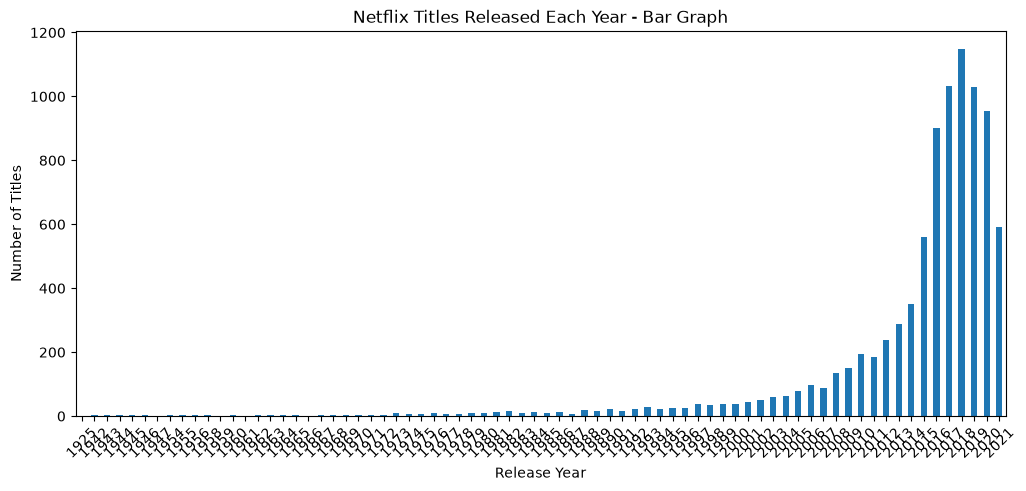

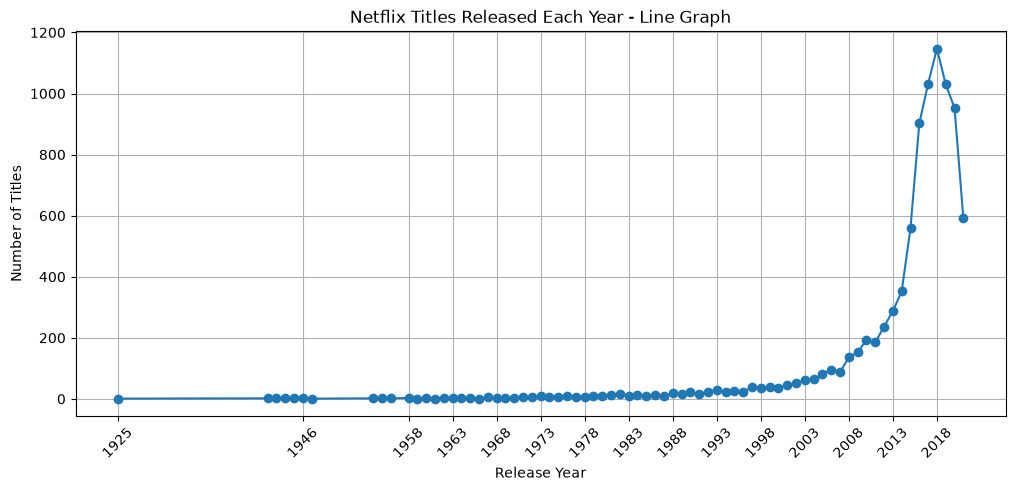

In [341]:
#now here use of Matplotlib:Python library used to create graphs and charts from data.
#matplot helps us to convert number into visual representation.

import matplotlib.pyplot as plt

# Count titles released each year
year_counts = df["release_year"].value_counts().sort_index()

# BAR GRAPH
plt.figure(figsize=(12,5))
year_counts.plot(kind="bar")

plt.title("Netflix Titles Released Each Year - Bar Graph")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()


# LINE GRAPH
plt.figure(figsize=(12,5))
year_counts.plot(kind="line", marker="o")

plt.title("Netflix Titles Released Each Year - Line Graph")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks(year_counts.index[::5], rotation=45)
plt.grid(True)
plt.show()

In [342]:
print(df["type"].value_counts())
print(df["type"].value_counts(normalize=True)*100)

type
Movie      6131
TV Show    2676
Name: count, dtype: int64
type
Movie      69.615079
TV Show    30.384921
Name: proportion, dtype: float64


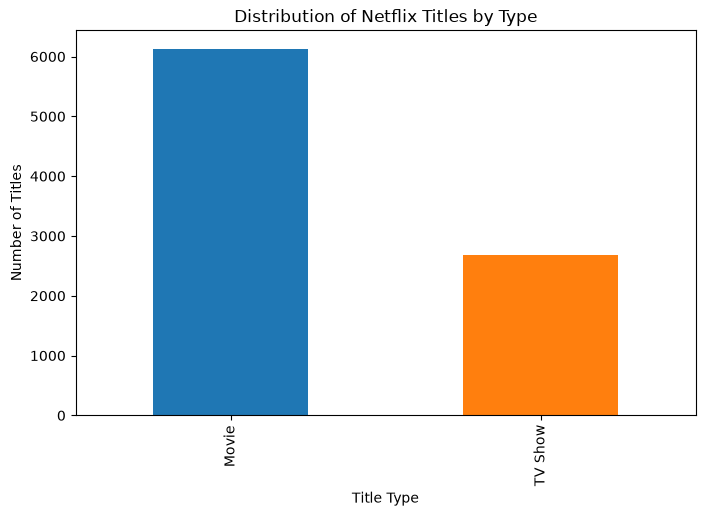

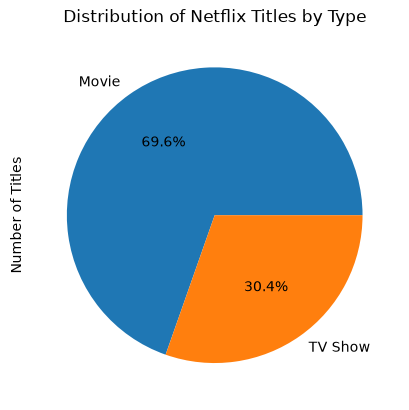

In [343]:
import matplotlib.pyplot as plt
df["type"].value_counts().plot(kind="bar",figsize=(8,5),color=["#1f77b4","#ff7f0e"])
plt.title("Distribution of Netflix Titles by Type")
plt.xlabel("Title Type")
plt.ylabel("Number of Titles")
plt.show()

#pie chart 
df["type"].value_counts().plot(kind="pie",autopct="%1.1f%%",color="#98a02c")
plt.title("Distribution of Netflix Titles by Type")
plt.ylabel("Number of Titles")
plt.show()


In [344]:
print(df["country"].value_counts().head(10))


country
United States     2818
India              972
Unknown            831
United Kingdom     419
Japan              245
South Korea        199
Canada             181
Spain              145
France             124
Mexico             110
Name: count, dtype: int64


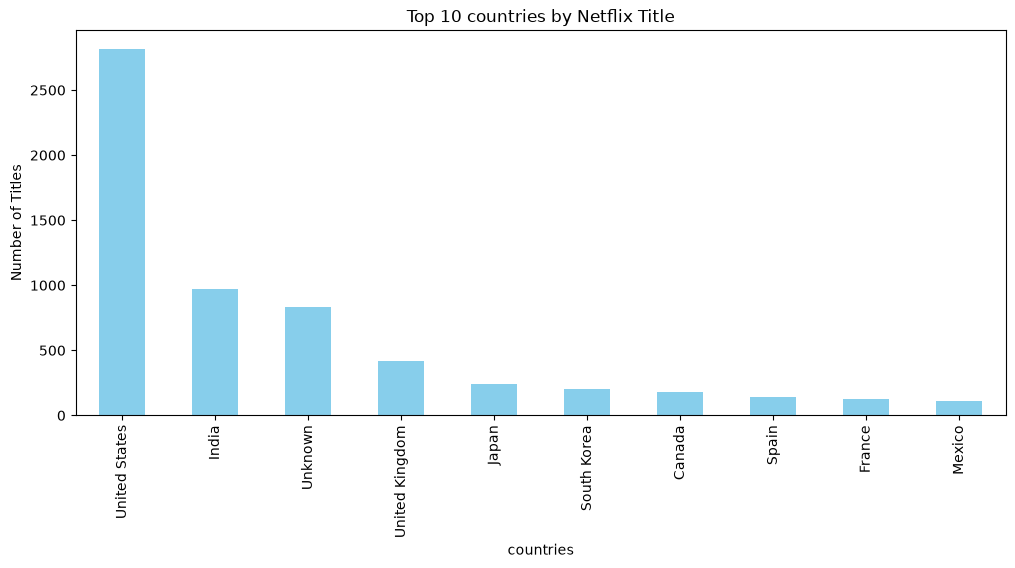

In [345]:
import matplotlib.pyplot as plt
country_counts=df["country"].value_counts().head(10)
plt.figure(figsize=(12,5))
country_counts.plot(kind="bar",color="skyblue")

plt.title("Top 10 countries by Netflix Title")
plt.xlabel("countries")
plt.ylabel("Number of Titles")
#plt.xticks(rotation=45)
plt.show()

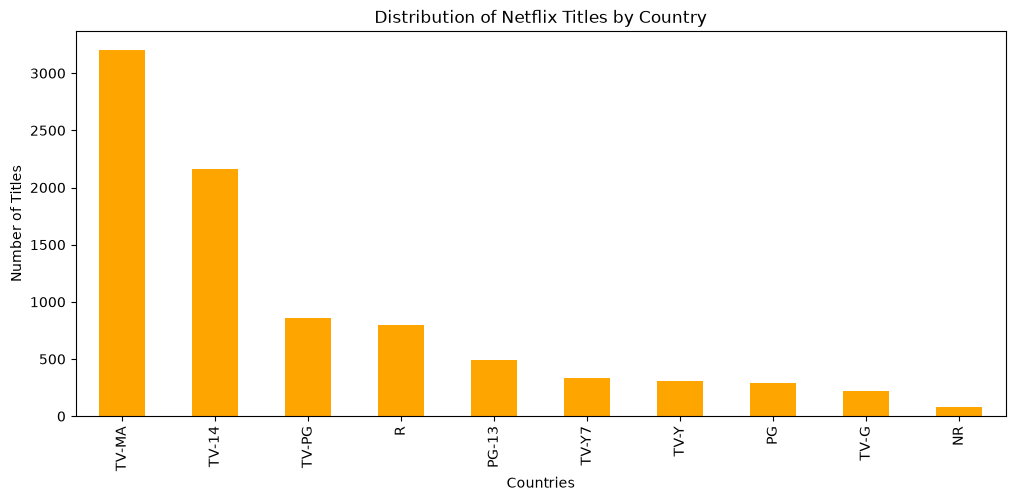

In [346]:
import matplotlib.pylab as plt
rating_counts = df["rating"].value_counts().head(10)
plt.figure(figsize=(12,5))
rating_counts.plot(kind="bar", color="orange")
plt.title("Distribution of Netflix Titles by Country")
plt.xlabel("Countries")
plt.ylabel("Number of Titles")
plt.show()

listed_in
Dramas, International Movies                        362
Documentaries                                       359
Stand-Up Comedy                                     334
Comedies, Dramas, International Movies              274
Dramas, Independent Movies, International Movies    252
Kids' TV                                            220
Children & Family Movies                            215
Children & Family Movies, Comedies                  201
Documentaries, International Movies                 186
Dramas, International Movies, Romantic Movies       180
Name: count, dtype: int64


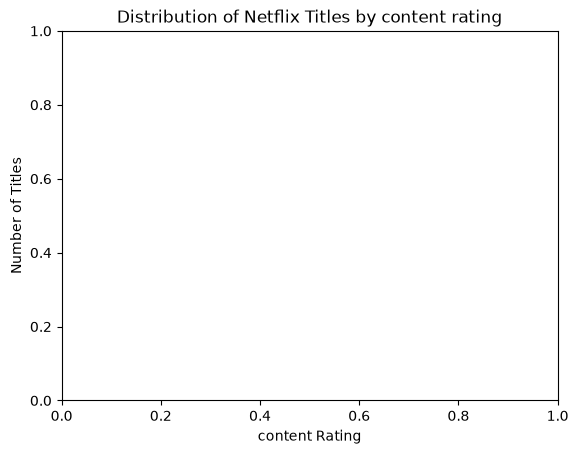

In [347]:
plt.title("Distribution of Netflix Titles by content rating")
plt.xlabel("content Rating")
plt.ylabel("Number of Titles")
print(df["listed_in"].value_counts().head(10))

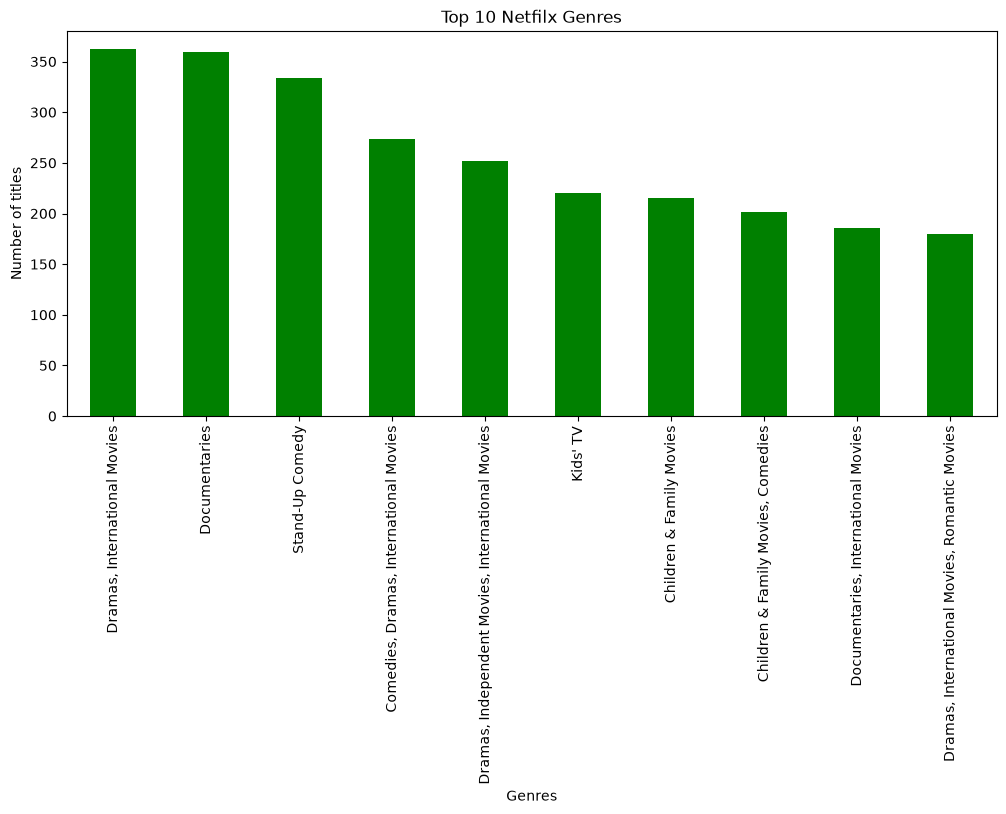

In [348]:
import matplotlib.pylab as plt
genre_counts=df["listed_in"].value_counts().head(10)
plt.figure(figsize=(12,5))
genre_counts.plot(kind="bar",color="green")

plt.title("Top 10 Netfilx Genres")
plt.xlabel("Genres")
plt.ylabel("Number of titles")
plt.show()


In [349]:
genre_list=df["listed_in"].dropna().str.split(",")   #dropna: use for remove missing values
individual_genres=genre_list.explode()            #convert lists into separate ROWS
individual_genres=individual_genres.str.strip()           #remove extra space 
print(individual_genres.value_counts().head(10))


listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


In [350]:
print(df["type"].value_counts())

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


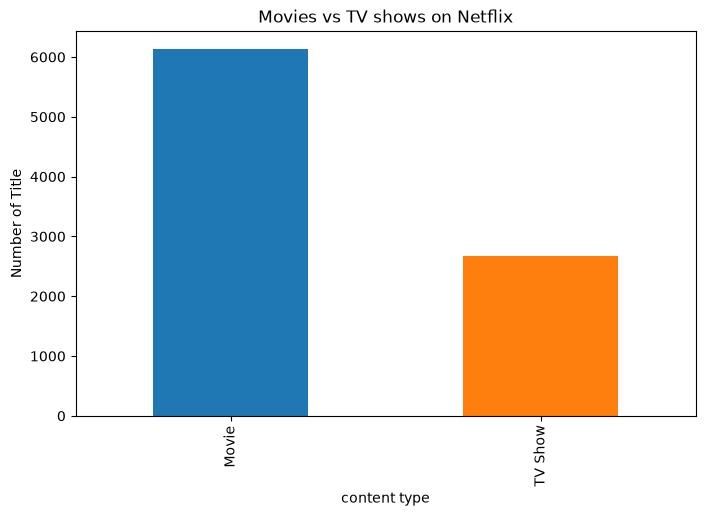

In [351]:
df["type"].value_counts().plot(kind="bar",figsize=(8,5),color=["#1f77b4","#ff7f0e"])
plt.title("Movies vs TV shows on Netflix")
plt.xlabel("content type")
plt.ylabel("Number of Title")
plt.show()

In [352]:
yearly_content=df.groupby(["release_year","type"]).size().unstack()
print(yearly_content.tail(10))

type          Movie  TV Show
release_year                
2012          173.0     64.0
2013          225.0     63.0
2014          264.0     88.0
2015          398.0    162.0
2016          658.0    244.0
2017          767.0    265.0
2018          767.0    380.0
2019          633.0    397.0
2020          517.0    436.0
2021          277.0    315.0


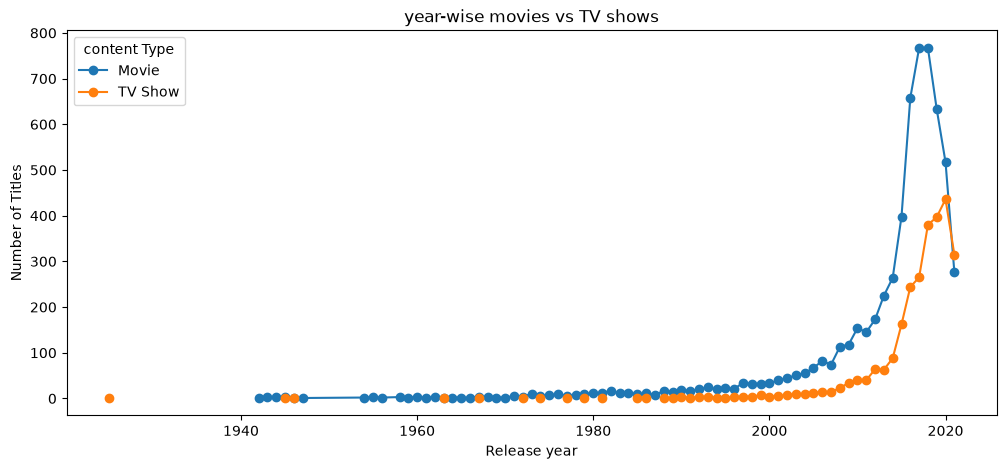

In [353]:
yearly_content.plot(
    kind="line",
    marker="o",
    figsize=(12,5)
)
plt.title("year-wise movies vs TV shows")
plt.xlabel("Release year")
plt.ylabel("Number of Titles")
plt.legend(title="content Type")
plt.show()

In [354]:
top_countries=df["country"].value_counts().head(10)
print(top_countries)

country
United States     2818
India              972
Unknown            831
United Kingdom     419
Japan              245
South Korea        199
Canada             181
Spain              145
France             124
Mexico             110
Name: count, dtype: int64


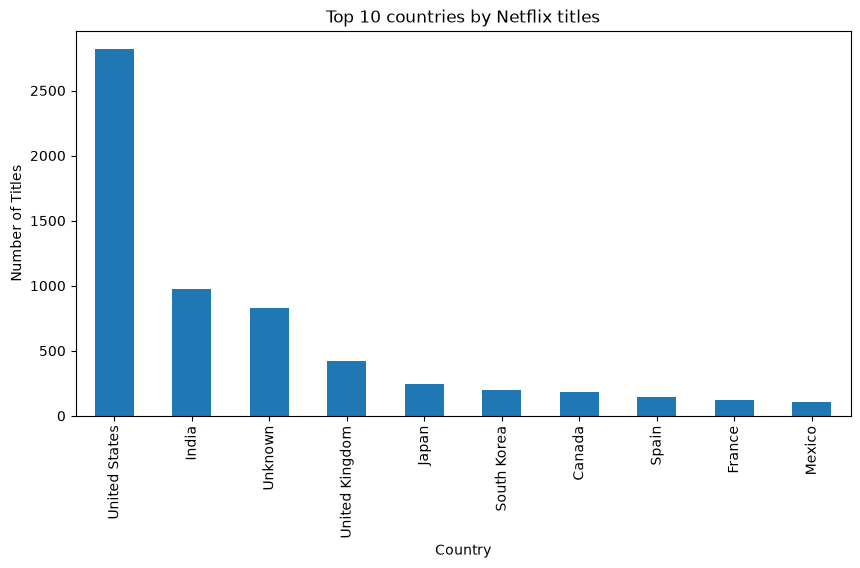

In [355]:
top_countries.plot(kind="bar",figsize=(10,5))

plt.title("Top 10 countries by Netflix titles")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.show()

In [356]:
country_list = df.loc[
    df["country"] != "Unknown", "country"
].dropna().str.split(",")

individual_countries = country_list.explode()

individual_countries = individual_countries.str.strip()

print(individual_countries.value_counts().head(10))

country
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


In [357]:
movies=df[df["type"] == "Movie"]
print(movies[["title","duration"]].head(10))

                                                title duration
0                                Dick Johnson Is Dead   90 min
6                    My Little Pony: A New Generation   91 min
7                                             Sankofa  125 min
9                                        The Starling  104 min
12                                       Je Suis Karl  127 min
13                   Confessions of an Invisible Girl   91 min
16  Europe's Most Dangerous Man: Otto Skorzeny in ...   67 min
18                                          Intrusion   94 min
22                                    Avvai Shanmughi  161 min
23       Go! Go! Cory Carson: Chrissy Takes the Wheel   61 min


In [358]:
print(df["type"].unique())
print(df["type"].value_counts(dropna=False))
print(df["type"].head(10).tolist())

<StringArray>
['Movie', 'TV Show']
Length: 2, dtype: str
type
Movie      6131
TV Show    2676
Name: count, dtype: int64
['Movie', 'TV Show', 'TV Show', 'TV Show', 'TV Show', 'TV Show', 'Movie', 'Movie', 'TV Show', 'Movie']


In [359]:
movies = df.loc[df["type"] == "Movie"].copy()

print("Movie dataset shape:", movies.shape)

print(movies[["title", "duration"]].head(10))

Movie dataset shape: (6131, 12)
                                                title duration
0                                Dick Johnson Is Dead   90 min
6                    My Little Pony: A New Generation   91 min
7                                             Sankofa  125 min
9                                        The Starling  104 min
12                                       Je Suis Karl  127 min
13                   Confessions of an Invisible Girl   91 min
16  Europe's Most Dangerous Man: Otto Skorzeny in ...   67 min
18                                          Intrusion   94 min
22                                    Avvai Shanmughi  161 min
23       Go! Go! Cory Carson: Chrissy Takes the Wheel   61 min


In [360]:
print(movies["duration"].isnull().sum())
print(movies["duration"].unique()[:20])

0
<StringArray>
[ '90 min',  '91 min', '125 min', '104 min', '127 min',  '67 min',  '94 min',
 '161 min',  '61 min', '166 min', '147 min', '103 min',  '97 min', '106 min',
 '111 min', '110 min', '105 min',  '96 min', '124 min', '116 min']
Length: 20, dtype: str


In [361]:
movies["duration_minutes"] = movies["duration"].str.replace(" min", "", regex=False)

movies["duration_minutes"] = pd.to_numeric(movies["duration_minutes"], errors="coerce")

print(movies[["title", "duration", "duration_minutes"]].head(10))

                                                title duration  \
0                                Dick Johnson Is Dead   90 min   
6                    My Little Pony: A New Generation   91 min   
7                                             Sankofa  125 min   
9                                        The Starling  104 min   
12                                       Je Suis Karl  127 min   
13                   Confessions of an Invisible Girl   91 min   
16  Europe's Most Dangerous Man: Otto Skorzeny in ...   67 min   
18                                          Intrusion   94 min   
22                                    Avvai Shanmughi  161 min   
23       Go! Go! Cory Carson: Chrissy Takes the Wheel   61 min   

    duration_minutes  
0               90.0  
6               91.0  
7              125.0  
9              104.0  
12             127.0  
13              91.0  
16              67.0  
18              94.0  
22             161.0  
23              61.0  


In [362]:
average_duration = movies["duration_minutes"].mean()

maximum_duration = movies["duration_minutes"].max()

minimum_duration = movies["duration_minutes"].min()

print("Average Movie Duration:", average_duration)
print("Longest Movie Duration:", maximum_duration)
print("Shortest Movie Duration:", minimum_duration)

Average Movie Duration: 99.57718668407311
Longest Movie Duration: 312.0
Shortest Movie Duration: 3.0


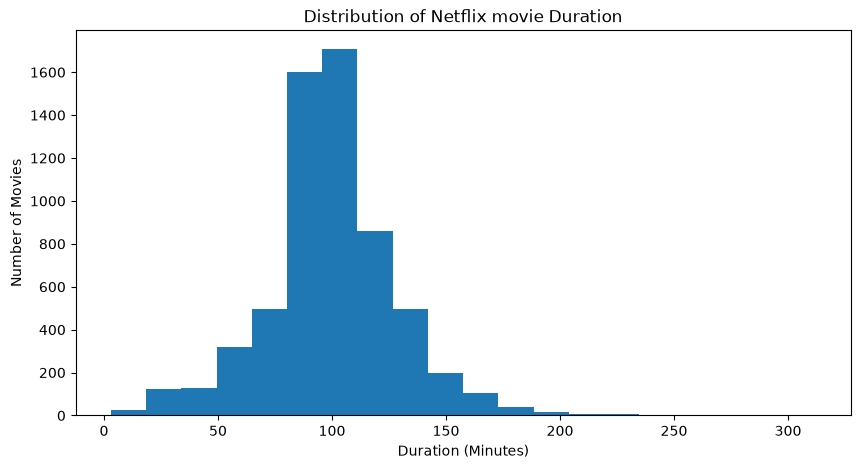

In [363]:
plt.figure(figsize=(10,5))
plt.hist(movies["duration_minutes"].dropna(),bins=20)
plt.title("Distribution of Netflix movie Duration")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Movies")
plt.show()

In [364]:
tv_shows = df[df["type"] == "TV Show"].copy()

print(tv_shows.shape)

print(tv_shows[["title", "duration"]].head(10))

(2676, 12)
                                  title   duration
1                         Blood & Water  2 Seasons
2                             Ganglands   1 Season
3                 Jailbirds New Orleans   1 Season
4                          Kota Factory  2 Seasons
5                         Midnight Mass   1 Season
8         The Great British Baking Show  9 Seasons
10  Vendetta: Truth, Lies and The Mafia   1 Season
11                     Bangkok Breaking   1 Season
14      Crime Stories: India Detectives   1 Season
15                    Dear White People  4 Seasons


In [365]:
tv_shows["seasons"] = tv_shows["duration"].str.replace(
    " Seasons", "", regex=False
)

tv_shows["seasons"] = tv_shows["seasons"].str.replace(
    " Season", "", regex=False
)

tv_shows["seasons"] = pd.to_numeric(
    tv_shows["seasons"], errors="coerce"
)

print(tv_shows[["title", "duration", "seasons"]].head(10))

                                  title   duration  seasons
1                         Blood & Water  2 Seasons        2
2                             Ganglands   1 Season        1
3                 Jailbirds New Orleans   1 Season        1
4                          Kota Factory  2 Seasons        2
5                         Midnight Mass   1 Season        1
8         The Great British Baking Show  9 Seasons        9
10  Vendetta: Truth, Lies and The Mafia   1 Season        1
11                     Bangkok Breaking   1 Season        1
14      Crime Stories: India Detectives   1 Season        1
15                    Dear White People  4 Seasons        4


In [366]:
average_seasons = tv_shows["seasons"].mean()

maximum_seasons = tv_shows["seasons"].max()

minimum_seasons = tv_shows["seasons"].min()

print("Average Seasons:", average_seasons)
print("Maximum Seasons:", maximum_seasons)
print("Minimum Seasons:", minimum_seasons)

print(tv_shows["seasons"].value_counts().sort_index())

Average Seasons: 1.764947683109118
Maximum Seasons: 17
Minimum Seasons: 1
seasons
1     1793
2      425
3      199
4       95
5       65
6       33
7       23
8       17
9        9
10       7
11       2
12       2
13       3
15       2
17       1
Name: count, dtype: int64


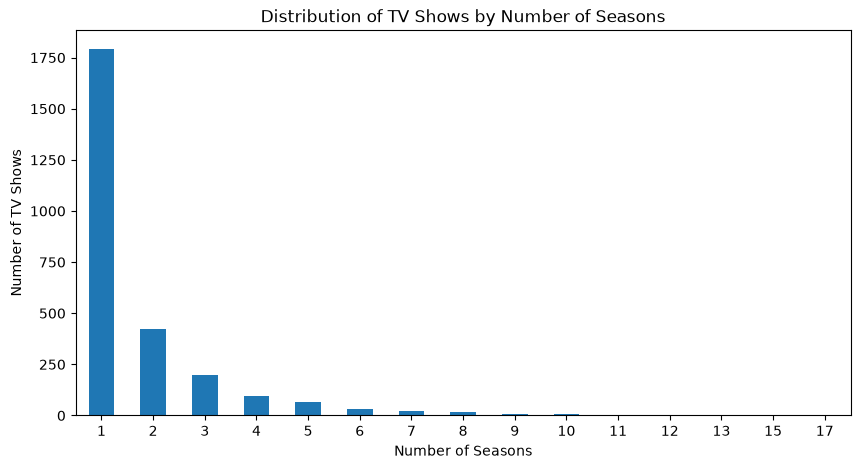

In [367]:
season_counts = tv_shows["seasons"].value_counts().sort_index()

season_counts.plot(kind="bar", figsize=(10,5))

plt.title("Distribution of TV Shows by Number of Seasons")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of TV Shows")
plt.xticks(rotation=0)
plt.show()

In [368]:
top_ratings = df["rating"].value_counts().head(10)

print(top_ratings)

rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: count, dtype: int64


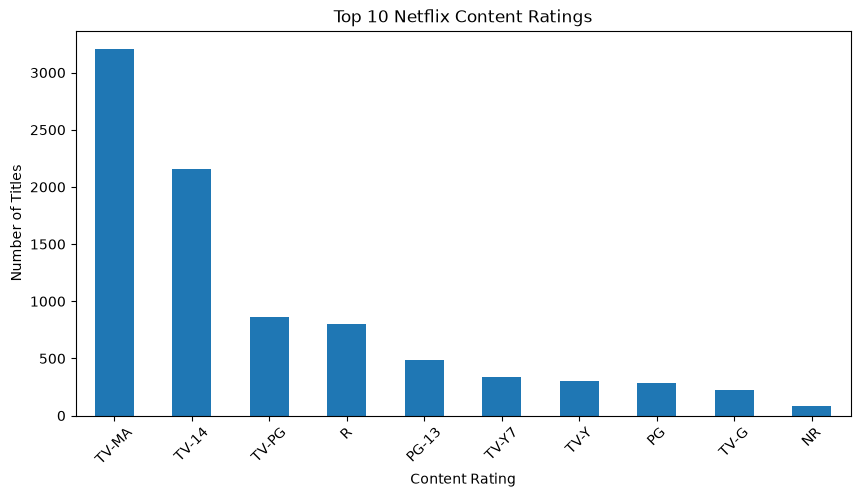

In [369]:
top_ratings = df["rating"].value_counts().head(10)

top_ratings.plot(kind="bar", figsize=(10,5))

plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()

In [370]:
rating_type=df.groupby(["type","rating"]).size().unstack()
print(rating_type)

rating      G  NC-17    NR  Not Rated     PG  PG-13      R   TV-14   TV-G  \
type                                                                        
Movie    41.0    3.0  75.0        5.0  287.0  490.0  797.0  1427.0  126.0   
TV Show   NaN    NaN   5.0        2.0    NaN    NaN    2.0   733.0   94.0   

rating    TV-MA  TV-PG   TV-Y  TV-Y7  TV-Y7-FV   UR  
type                                                 
Movie    2062.0  540.0  131.0  139.0       5.0  3.0  
TV Show  1145.0  323.0  176.0  195.0       1.0  NaN  


In [371]:
print(df[df["rating"].str.contains("min", na=False)]
      [["title","type","rating","duration"]])


Empty DataFrame
Columns: [title, type, rating, duration]
Index: []


In [372]:
mask=df["rating"].str.contains("min", na=False)   #find incorrect rate
df.loc[mask,"duration"] = df.loc[mask,"rating"]   #move duration into column
df.loc[mask,"rating"]=pd.NA  # replace inccorect rating

print(df.loc[mask,["title","type","rating","duration"]])

Empty DataFrame
Columns: [title, type, rating, duration]
Index: []


In [373]:
rating_type = df.groupby(["type", "rating"]).size().unstack()
print(rating_type)

rating      G  NC-17    NR  Not Rated     PG  PG-13      R   TV-14   TV-G  \
type                                                                        
Movie    41.0    3.0  75.0        5.0  287.0  490.0  797.0  1427.0  126.0   
TV Show   NaN    NaN   5.0        2.0    NaN    NaN    2.0   733.0   94.0   

rating    TV-MA  TV-PG   TV-Y  TV-Y7  TV-Y7-FV   UR  
type                                                 
Movie    2062.0  540.0  131.0  139.0       5.0  3.0  
TV Show  1145.0  323.0  176.0  195.0       1.0  NaN  


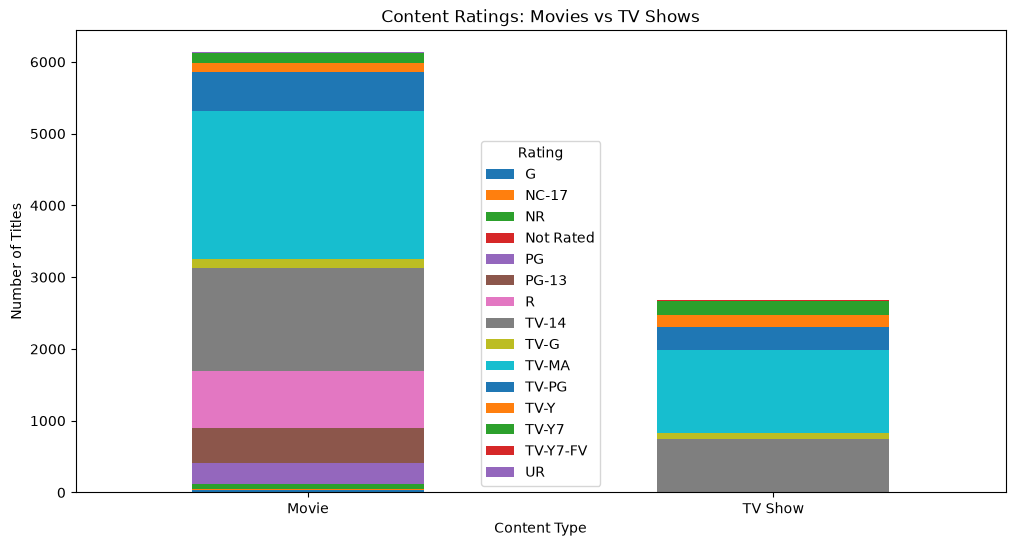

In [374]:
rating_type.plot(
    kind="bar",
    figsize=(12,6),
    stacked=True
)

plt.title("Content Ratings: Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.legend(title="Rating")
plt.show()

In [375]:
type_count=df["type"].value_counts()
print(type_count)

type_percentage = df["type"].value_counts(normalize=True) * 100
print(type_percentage)

type
Movie      6131
TV Show    2676
Name: count, dtype: int64
type
Movie      69.615079
TV Show    30.384921
Name: proportion, dtype: float64


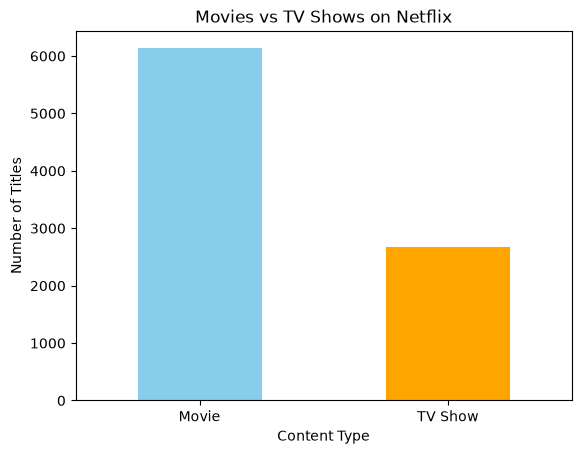

In [376]:
import matplotlib.pyplot as plt

df["type"].value_counts().plot(kind="bar", color=["skyblue", "orange"])

plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.show()

In [377]:
year_type = df.groupby(["release_year", "type"]).size().unstack()
print(year_type.tail(15))

type          Movie  TV Show
release_year                
2007           74.0     14.0
2008          113.0     23.0
2009          118.0     34.0
2010          154.0     40.0
2011          145.0     40.0
2012          173.0     64.0
2013          225.0     63.0
2014          264.0     88.0
2015          398.0    162.0
2016          658.0    244.0
2017          767.0    265.0
2018          767.0    380.0
2019          633.0    397.0
2020          517.0    436.0
2021          277.0    315.0


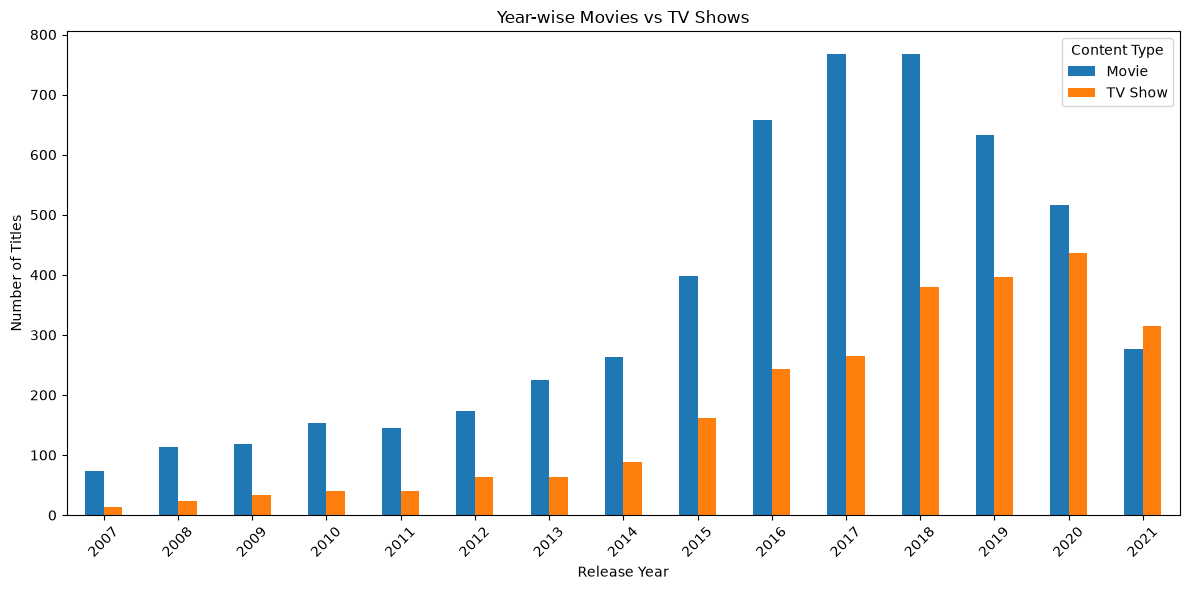

In [378]:
year_type.tail(15).plot(kind="bar", figsize=(12,6))

plt.title("Year-wise Movies vs TV Shows")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()

In [379]:
genre_counts=df["listed_in"].value_counts().head(10)
print(genre_counts)

listed_in
Dramas, International Movies                        362
Documentaries                                       359
Stand-Up Comedy                                     334
Comedies, Dramas, International Movies              274
Dramas, Independent Movies, International Movies    252
Kids' TV                                            220
Children & Family Movies                            215
Children & Family Movies, Comedies                  201
Documentaries, International Movies                 186
Dramas, International Movies, Romantic Movies       180
Name: count, dtype: int64


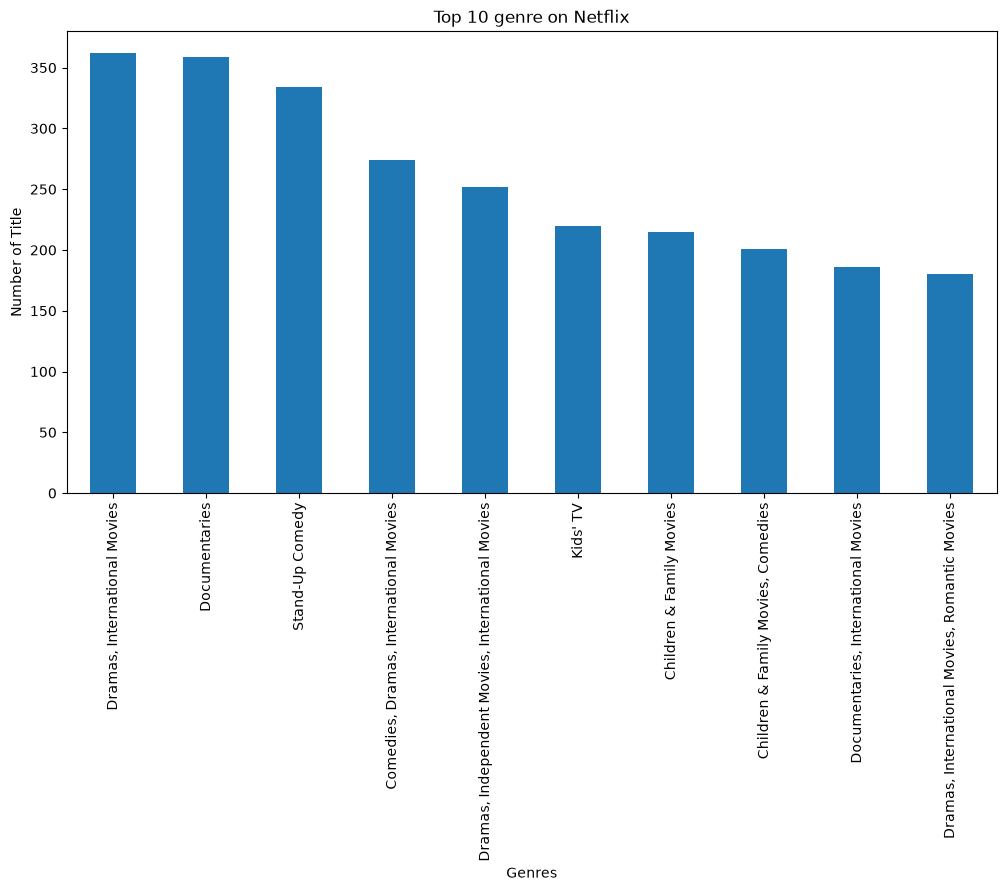

In [380]:
genre_counts.plot(kind="bar",figsize=(12,6))

plt.title("Top 10 genre on Netflix")
plt.xlabel("Genres")
plt.ylabel("Number of Title")
plt.show()


In [381]:
type_count=df["type"].value_counts()
print(type_count)
type_percentage = (type_count / len(df)) * 100
print(type_percentage)

type
Movie      6131
TV Show    2676
Name: count, dtype: int64
type
Movie      69.615079
TV Show    30.384921
Name: count, dtype: float64


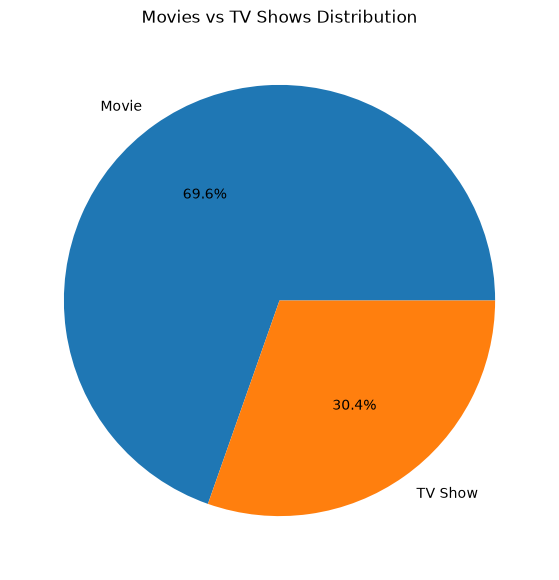

In [382]:
type_count.plot(kind="pie", autopct="%1.1f%%", figsize=(7,7))

plt.title("Movies vs TV Shows Distribution")
plt.ylabel("")
plt.show()

In [383]:
print("DATASET SHAPE:")
print(df.shape)

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nDATASET INFORMATION:")
df.info()

print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())

DATASET SHAPE:
(8807, 12)

COLUMN NAMES:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8807 non-null   str           
 1   type          8807 non-null   str           
 2   title         8807 non-null   str           
 3   director      8807 non-null   str           
 4   cast          8807 non-null   str           
 5   country       8807 non-null   str           
 6   date_added    8709 non-null   datetime64[us]
 7   release_year  8807 non-null   int64         
 8   rating        8807 non-null   str           
 9   duration      8807 non-null   str           
 10  listed_in     8807 non-null   str           
 11  description   8807 non-null   str           
d

In [384]:
director_count = df[df["director"] != "Unknown"]["director"].str.split(",").explode().str.strip().value_counts()

print("Top 10 Directors on Netflix:")
print(director_count.head(10))

Top 10 Directors on Netflix:
director
Not specified          2634
Rajiv Chilaka            22
Jan Suter                21
Raúl Campos              19
Suhas Kadav              16
Marcus Raboy             16
Jay Karas                15
Cathy Garcia-Molina      13
Youssef Chahine          12
Martin Scorsese          12
Name: count, dtype: int64


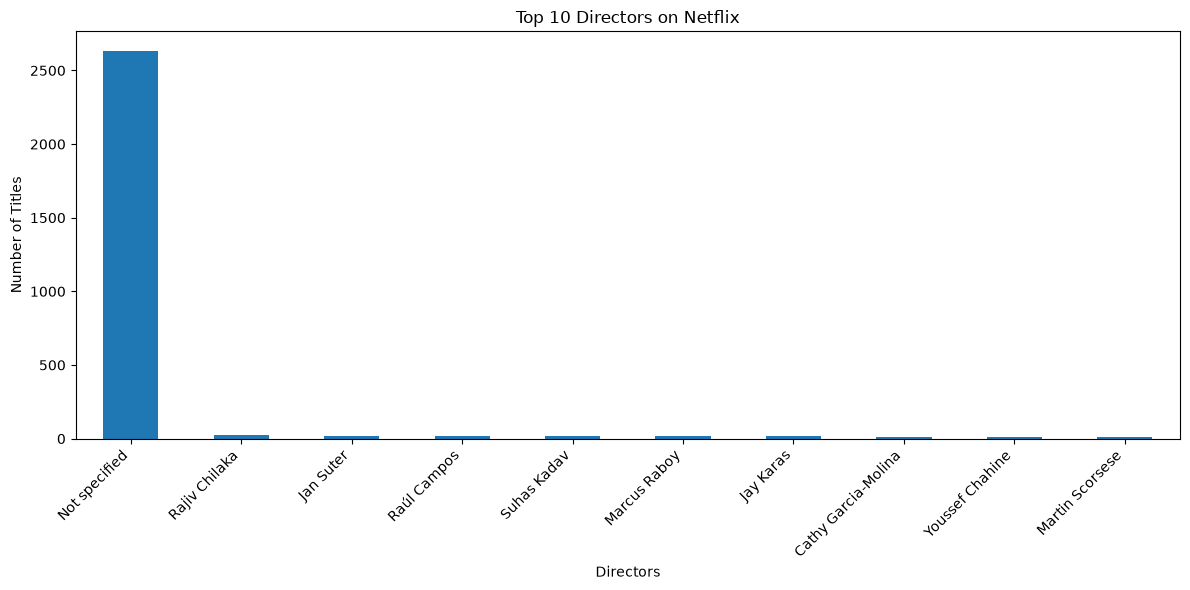

In [385]:
director_count.head(10).plot(
    kind="bar",
    figsize=(12,6)
)

plt.title("Top 10 Directors on Netflix")
plt.xlabel("Directors")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [386]:
cast_count = (
    df[df["cast"] != "Unknown"]["cast"]
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
)

print("Top 10 Actors on Netflix:")
print(cast_count.head(10))

Top 10 Actors on Netflix:
cast
Not Available       825
Anupam Kher          43
Shah Rukh Khan       35
Julie Tejwani        33
Naseeruddin Shah     32
Takahiro Sakurai     32
Rupa Bhimani         31
Akshay Kumar         30
Om Puri              30
Yuki Kaji            29
Name: count, dtype: int64


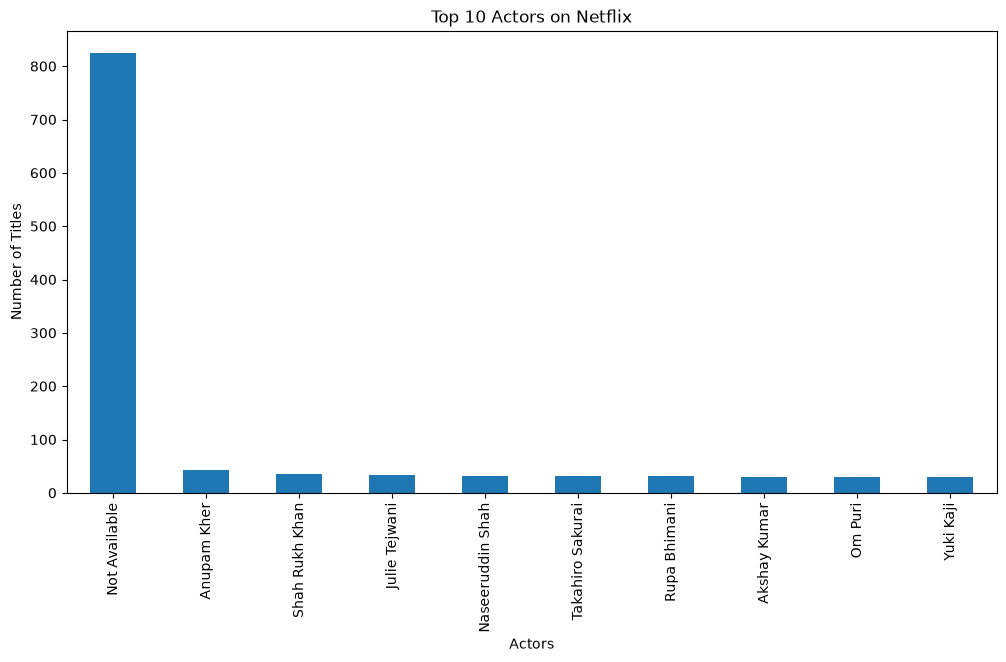

In [387]:
cast_count.head(10).plot(
    kind="bar",
    figsize=(12,6)
)

plt.title("Top 10 Actors on Netflix")
plt.xlabel("Actors")
plt.ylabel("Number of Titles")
plt.show()

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


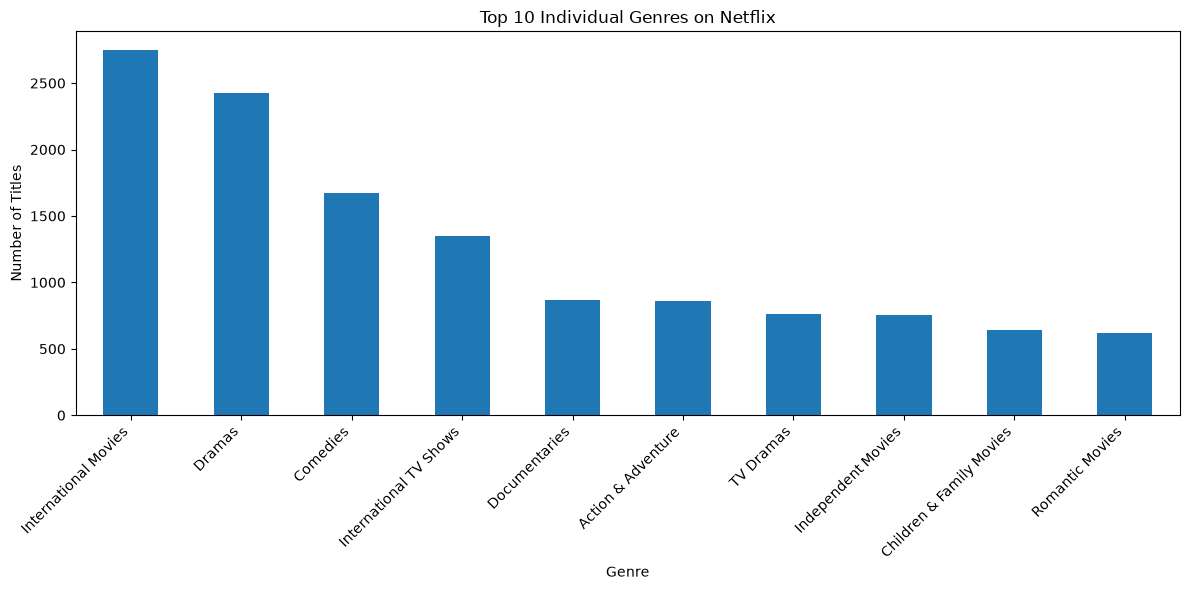

In [388]:
genre_list = df["listed_in"].str.split(", ").explode()

top_genres = genre_list.value_counts().head(10)

print(top_genres)

top_genres.plot(kind="bar", figsize=(12,6))

plt.title("Top 10 Individual Genres on Netflix")
plt.xlabel("Genre")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      10
2014.0      23
2015.0      73
2016.0     418
2017.0    1164
2018.0    1625
2019.0    1999
2020.0    1878
2021.0    1498
Name: count, dtype: int64


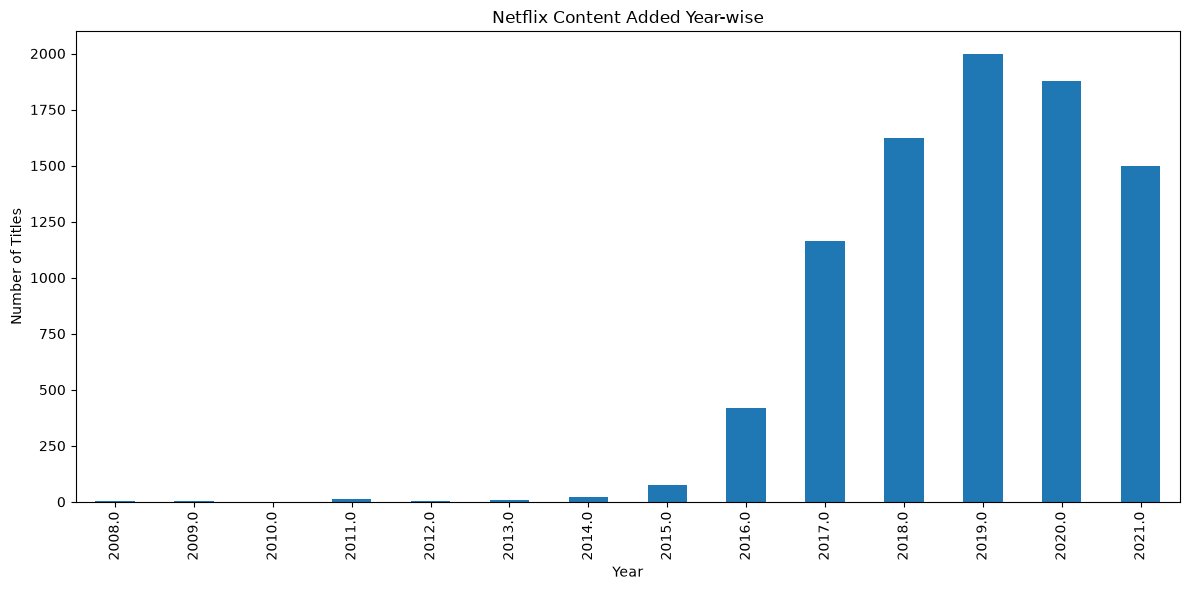

In [389]:
df["year_added"] = df["date_added"].dt.year

year_added_count = df["year_added"].value_counts().sort_index()

print(year_added_count)

year_added_count.plot(kind="bar", figsize=(12,6))

plt.title("Netflix Content Added Year-wise")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

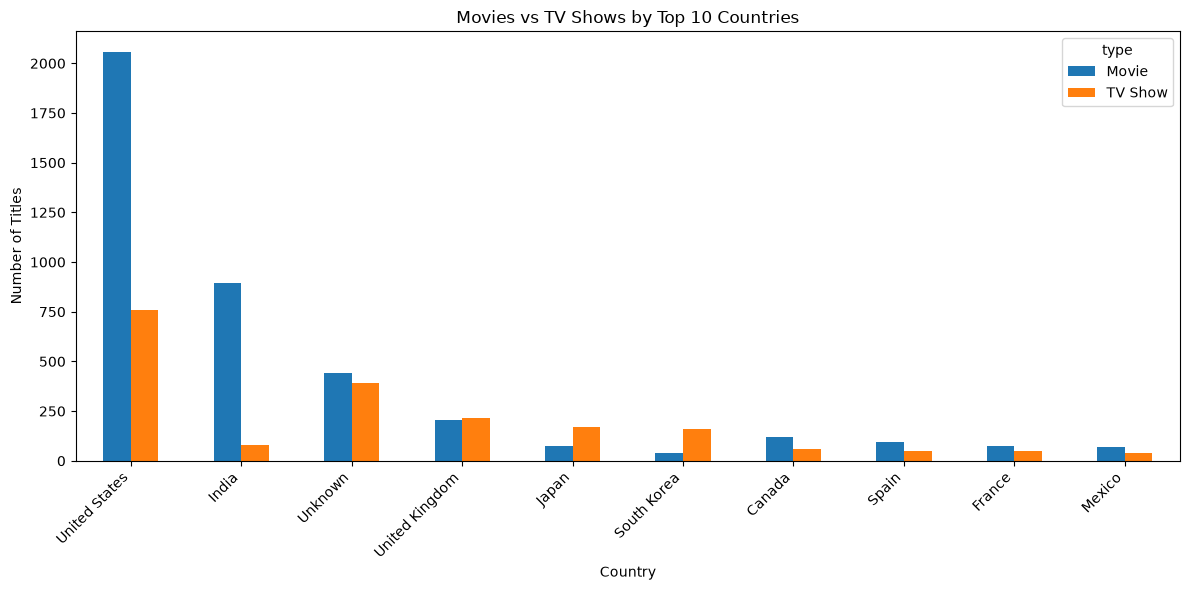

In [390]:
country_type = pd.crosstab(df["country"], df["type"])

top_countries = country_type.sum(axis=1).nlargest(10).index

country_type.loc[top_countries].plot(
    kind="bar",
    figsize=(12,6)
)

plt.title("Movies vs TV Shows by Top 10 Countries")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [391]:
df.to_csv("netflix_cleaned.csv", index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [392]:
print("========== NETFLIX DATA ANALYSIS: FINAL INSIGHTS ==========")

print("\n1. Total Netflix Titles:", len(df))

print("\n2. Total Movies:", (df["type"] == "Movie").sum())

print("\n3. Total TV Shows:", (df["type"] == "TV Show").sum())

print("\n4. Most Common Content Type:", df["type"].mode()[0])

print("\n5. Top Country:", country_counts.index[0])

print("\n6. Most Common Rating:", rating_counts.index[0])

print("\n7. Most Popular Genre:", genre_counts.index[0])

movies = df[df["type"] == "Movie"].copy()
movies["duration_num"] = pd.to_numeric(
    movies["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)
print("\n8. Average Movie Duration:",
      round(movies["duration_num"].mean(), 2), "minutes")
       
tv_shows = df[df["type"] == "TV Show"].copy()
tv_shows["seasons"] = pd.to_numeric(
    tv_shows["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)
print("\n9. Most Common TV Show Seasons:",
      tv_shows["seasons"].mode()[0])

director_count = df["director"].dropna()
director_count = director_count[~director_count.isin(["Not specified", "Not Available", "Unknown"])]
director_count = director_count.str.split(", ").explode().value_counts()

cast_count = df["cast"].dropna()
cast_count = cast_count[~cast_count.isin(["Not specified", "Not Available", "Unknown"])]
cast_count = cast_count.str.split(", ").explode().value_counts()

#.isin() checks whether a value belongs to the given list.
#~ means NOT (opposite).
print("\n10. Top Director:", director_count.index[0])

print("\n11. Top Actor:", cast_count.index[0])

print("\n========== END OF ANALYSIS ==========")

========== NETFLIX DATA ANALYSIS: FINAL INSIGHTS ==========

1. Total Netflix Titles: 8807

2. Total Movies: 6131

3. Total TV Shows: 2676

4. Most Common Content Type: Movie

5. Top Country: United States

6. Most Common Rating: TV-MA

7. Most Popular Genre: Dramas, International Movies

8. Average Movie Duration: 99.58 minutes

9. Most Common TV Show Seasons: 1

10. Top Director: Rajiv Chilaka

11. Top Actor: Anupam Kher

========== END OF ANALYSIS ==========
